In [2]:
%pip install scikit-learn

  Obtaining dependency information for scikit-learn from https://files.pythonhosted.org/packages/69/46/f8b95a7a16fd13b458401d5e85a63d88ecb3679f3649812d5fdbea4c8357/scikit_learn-1.9.1-cp311-cp311-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata
  Obtaining dependency information for scipy>=1.10.0 from https://files.pythonhosted.org/packages/09/7d/af933f0f6e0767995b4e2d705a0665e454d1c19402aa7e895de3951ebb04/scipy-1.17.1-cp311-cp311-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.1/62.1 kB 437.9 kB/s eta 0:00:0000:01
  Obtaining dependency information for joblib>=1.4.0 from https://files.pythonhosted.org/packages/18/53/84099323c2ec4be98d935f63c033ac4151ee83836ca1050ede3b3aadf155/joblib-1.6.0-py3-none-any.whl.metadata
  Obtaining dependency information for narwhals>=2.0.1 from https://files.pythonhosted.org/packages/40/b5/1b84b2c784db76d69442334bc8b8748c840f13ca53be086f4f250ad4a0bc/narwhals-2.26.0-py3-none-any.whl.metadata
  

In [3]:
%pip install xgboost

  Obtaining dependency information for xgboost from https://files.pythonhosted.org/packages/79/98/679de17c2caa4fd3b0b4386ecf7377301702cb0afb22930a07c142fcb1d8/xgboost-3.2.0-py3-none-manylinux_2_28_x86_64.whl.metadata
  Obtaining dependency information for nvidia-nccl-cu12 from https://files.pythonhosted.org/packages/f3/f8/9dce3698eed6fae28078eb38f748feb1665767693d8017c099de9fbf0b08/nvidia_nccl_cu12-2.32.3-py3-none-manylinux_2_27_x86_64.whl.metadata
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.7/131.7 MB 18.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 351.5/351.5 MB 8.7 MB/s eta 0:00:00:00:0100:01

[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [29]:
import pandas as pd
import numpy as np

from rdkit import Chem
from rdkit.Chem import Descriptors

from sklearn.metrics import mean_squared_error, r2_score

import xgboost as xgb

In [2]:
df = pd.read_csv("data/dockstring-dataset.tsv", sep="\t")
data = df[["smiles", "JAK2", "LCK"]].dropna().copy()

In [6]:
data.head()

,smiles,JAK2,LCK
0,C1=C(C2=C(C=C1O)OC(C(C2=O)=O)C3=CC=C(C(=C3)O)O)O,-9.4,-8.1
1,O=S(=O)(N1CCNCCC1)C2=CC=CC=3C2=CC=NC3,-8.1,-7.8
2,C=1C=C2S/C(/N(CC)C2=CC1OC)=C\C(=O)C,-6.6,-6.1
3,C=1(N=C(C=2C=NC=CC2)C=CN1)NC=3C=C(NC(C4=CC=C(C...,-10.6,-9.3
4,C1=CC=2C(=CNC2C=C1)C=3C=CN=CC3,-7.9,-6.8


Convert smiles into numerical features for X

In [3]:
from rdkit.Chem import rdFingerprintGenerator
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

test_mol = Chem.MolFromSmiles(data["smiles"].iloc[0])
test_fp = morgan_gen.GetFingerprint(test_mol)


In [5]:
print(test_fp)
len(test_fp)

2048

In [8]:
test_fp.GetNumOnBits()

35

In [4]:
test_array = np.array(test_fp)
test_array.shape

(2048,)

In [5]:
test_array[:50]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0])

In [7]:
def smiles_to_fp(smiles, morgan):
    mol =  Chem.MolFromSmiles(smiles)
    fp = morgan.GetFingerprint(mol)
    return np.array(fp)

fingerprint = [smiles_to_fp(smiles, morgan_gen) for smiles in data["smiles"]]

In [8]:
X = np.stack(fingerprint)
X.shape

(260149, 2048)

In [9]:
y = data["JAK2"].to_numpy()
y.shape

(260149,)

In [10]:
from rdkit.Chem.Scaffolds import MurckoScaffold

In [11]:
test_mol = Chem.MolFromSmiles(data["smiles"].iloc[0])

scaffold = MurckoScaffold.MurckoScaffoldSmiles(
    mol=test_mol
)

scaffold

'O=C1C(=O)C(c2ccccc2)Oc2ccccc21'

In [12]:
# Extract the core molecular scaffold from a SMILES string.
# Molecules with the same scaffold will be kept in the same group
# so similar molecular cores do not appear in both training and test data.
def get_scaffold(smiles):
    # Convert the SMILES string into an RDKit molecule
    mol = Chem.MolFromSmiles(smiles)

    # Extract the Bemis-Murcko scaffold (the molecule's core framework)
    return MurckoScaffold.MurckoScaffoldSmiles(mol=mol)


# Test the function on the first molecule
get_scaffold(data["smiles"].iloc[0])

'O=C1C(=O)C(c2ccccc2)Oc2ccccc21'

In [13]:
# Generate a scaffold for every molecule.
# Molecules with the same scaffold will have the same scaffold string.
data["scaffold"] = data["smiles"].apply(get_scaffold)

In [14]:
data[["smiles", "scaffold"]].head()

,smiles,scaffold
0,C1=C(C2=C(C=C1O)OC(C(C2=O)=O)C3=CC=C(C(=C3)O)O)O,O=C1C(=O)C(c2ccccc2)Oc2ccccc21
1,O=S(=O)(N1CCNCCC1)C2=CC=CC=3C2=CC=NC3,O=S(=O)(c1cccc2cnccc12)N1CCCNCC1
2,C=1C=C2S/C(/N(CC)C2=CC1OC)=C\C(=O)C,C=C1Nc2ccccc2S1
3,C=1(N=C(C=2C=NC=CC2)C=CN1)NC=3C=C(NC(C4=CC=C(C...,O=C(Nc1cccc(Nc2nccc(-c3cccnc3)n2)c1)c1ccc(CN2C...
4,C1=CC=2C(=CNC2C=C1)C=3C=CN=CC3,c1ccc2c(-c3ccncc3)c[nH]c2c1


In [15]:
data["scaffold"].nunique()

99407

In [16]:
from sklearn.model_selection import GroupShuffleSplit

train_test_split = GroupShuffleSplit(
    n_splits = 1, #one train test split
    test_size = 0.2, # 20% data is for testing
    random_state = 42 # makes the split reproducible
)

# Get the row indices for the training and testing sets.
# groups=data["scaffold"] ensures the same scaffold cannot appear in both sets.
train_idx, test_idx = next(
    train_test_split.split(
        X,
        y,
        groups=data["scaffold"]
    )
)

In [17]:
len(train_idx), len(test_idx)

(208979, 51170)

In [18]:
X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (208979, 2048)
X_test: (51170, 2048)
y_train: (208979,)
y_test: (51170,)


In [22]:
# XGBoost regression model for predicting JAK2 docking scores

model = xgb.XGBRegressor(
    objective = "reg:squarederror", #we're predicting a continuous number, the JAK2 score.
    n_estimators = 500, #build 500 trees sequentially.
    max_depth = 6, #limits how complicated each tree can become.
    learning_rate = 0.05, #controls how much each new tree changes the model.
    random_state = 42,
    n_jobs = -1 #use available CPU cores.
)

In [23]:
model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [30]:
y_pred = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("RMSE:", rmse)
print("R²:", r2)

RMSE: 0.5522518817348283
R²: 0.6663863687432805


### Model Evaluation

The XGBoost model achieved an **RMSE of 0.552** and an **R² of 0.666** on the scaffold-split test set.

- **RMSE (Root Mean Squared Error):** Measures the typical difference between the predicted and actual JAK2 docking scores. An RMSE of 0.552 means the model's predictions are typically off by roughly 0.55 docking-score units. Lower RMSE is better.

- **R² (Coefficient of Determination):** Measures how much of the variation in JAK2 docking scores is explained by the model. An R² of 0.666 means the model explains approximately **66.6% of the variation** in JAK2 docking scores in the test set. Higher R² is better, with 1 representing perfect predictions.

Because the test set was separated using molecular scaffolds, molecules sharing the same core scaffold were kept within the same split. This provides a more challenging evaluation of how well the model generalizes to molecules with unseen core structures.


In [31]:
model.save_model("jak2_xgboost.json")

In [32]:
#get the important values
feature_importance = model.feature_importances_
feature_importance.shape

(2048,)

In [ ]:
top_10 = np.argsort(feature_importance)[-10:][::-1]

top_10 #top 10 morgan fingerprint bit position

array([ 875, 1750, 1160, 1357, 1380, 1928,  294, 1855,  352,  926])

In [34]:
for bit in top_10:
    print(bit, feature_importance[bit])

875 0.029260641
1750 0.026267065
1160 0.02521064
1357 0.015414993
1380 0.011879884
1928 0.01128663
294 0.009649084
1855 0.009210676
352 0.008621286
926 0.0073624644


In [35]:
for i, fp in enumerate(fingerprint):
    if fp[875] == 1:
        print(i, data["smiles"].iloc[i])
        break

0 C1=C(C2=C(C=C1O)OC(C(C2=O)=O)C3=CC=C(C(=C3)O)O)O


In [36]:
mol = Chem.MolFromSmiles(data["smiles"].iloc[0])

additional_output = rdFingerprintGenerator.AdditionalOutput()
additional_output.AllocateBitInfoMap()

fp = morgan_gen.GetFingerprint(
    mol,
    additionalOutput=additional_output
)

bit_info = additional_output.GetBitInfoMap()

bit_info[875]

((4, 1), (0, 1), (18, 1))

In [37]:
from rdkit.Chem import Draw

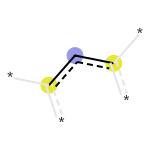

In [38]:
Draw.DrawMorganBit(mol, 875, bit_info)

### Feature Importance

The most important Morgan fingerprint feature identified by the XGBoost model was **bit 875**. Morgan fingerprint bits represent hashed local molecular environments rather than predefined chemical descriptors. RDKit was used to trace bit 875 back to an example molecular substructure.

Because Morgan fingerprints use hashing, a single bit can represent more than one molecular environment. Additionally, XGBoost feature importance measures how useful a feature was for prediction, but does not by itself indicate whether the feature increases or decreases the predicted JAK2 docking score.